# TA Chimaliro School Site Suitability

This notebook estimates suitable areas for potential primary-school sites within Traditional Authority (TA) Chimaliro, Thyolo District, Malawi.

The criteria in this example identify areas within 500 metres of a mapped main road, outside 2-kilometre buffers around mapped schools, and outside WDPA protected-area polygons. Review these thresholds and data assumptions before using the results for planning.

In [1]:
# --- Cell 1: Load Libraries and Data ---
import os
from pathlib import Path
import geopandas as gpd
import matplotlib.pyplot as plt
import folium

# Works when Jupyter starts in either the project folder or notebooks/.
PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name.lower() == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

ta_boundary = gpd.read_file(DATA_DIR / "ta_chimaliro.geojson")
roads = gpd.read_file(DATA_DIR / "roads.geojson")
schools = gpd.read_file(DATA_DIR / "existing_schools.geojson")
protected_areas = gpd.read_file(DATA_DIR / "protected_areas.geojson")

print(f"Loaded all four datasets from {DATA_DIR}")

Loaded all four datasets from C:\Users\Maya Chisale\chimaliiro-school-site-accessibility\data


In [2]:
# --- Cell 2: Reproject to UTM Zone 36S ---
TARGET_CRS = "EPSG:32736"  # WGS 84 / UTM Zone 36S; units are metres

ta_proj = ta_boundary.to_crs(TARGET_CRS)
roads_proj = gpd.clip(roads.to_crs(TARGET_CRS), ta_proj)
schools_proj = gpd.clip(schools.to_crs(TARGET_CRS), ta_proj)
protected_proj = gpd.clip(protected_areas.to_crs(TARGET_CRS), ta_proj)

print(f"Reprojected and clipped layers to {TARGET_CRS}")

Reprojected and clipped layers to EPSG:32736


In [3]:
# --- Cell 3: Buffers and Overlay ---
# Candidate locations must be within 500 m of a main road and more than 2 km from mapped schools.
road_buffer = gpd.GeoDataFrame(
    geometry=roads_proj.geometry.buffer(500), crs=TARGET_CRS
).dissolve()
school_buffer = gpd.GeoDataFrame(
    geometry=schools_proj.geometry.buffer(2000), crs=TARGET_CRS
).dissolve()

# WDPA includes point-only records as well as mapped boundaries. Only polygon
# records define an area that can be subtracted from candidate polygons.
protected_polygons = protected_proj[
    protected_proj.geometry.geom_type.isin(["Polygon", "MultiPolygon"])
]
protected_dissolved = protected_polygons.dissolve() if not protected_polygons.empty else None

candidate_areas = gpd.overlay(road_buffer, school_buffer, how="difference")
if protected_dissolved is not None and not protected_dissolved.empty:
    suitable_areas = gpd.overlay(candidate_areas, protected_dissolved, how="difference")
else:
    suitable_areas = candidate_areas

suitable_final = gpd.clip(suitable_areas, ta_proj)
print(f"Created {len(suitable_final)} suitable area feature(s)")

Created 1 suitable area feature(s)


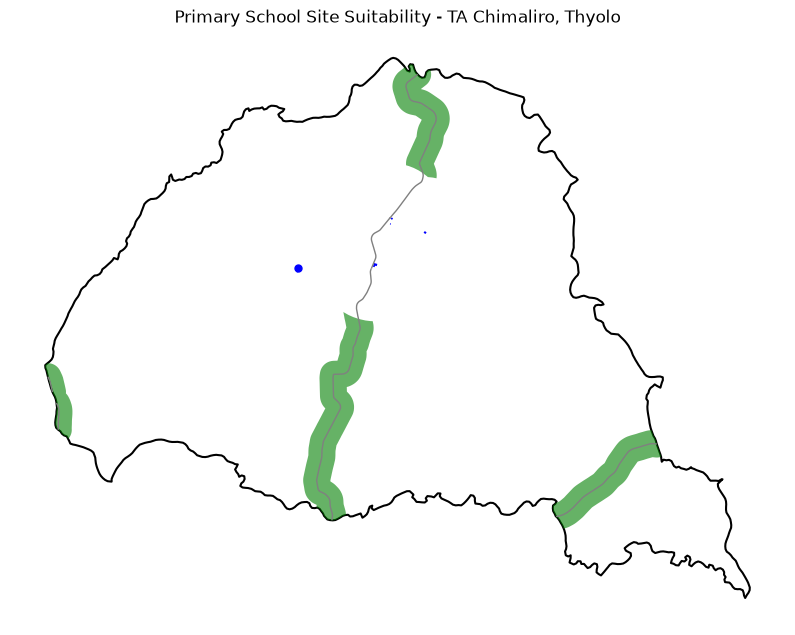

Static map saved to C:\Users\Maya Chisale\chimaliiro-school-site-accessibility\outputs\suitable_areas_map.png
Interactive map saved to C:\Users\Maya Chisale\chimaliiro-school-site-accessibility\outputs\interactive_map.html


In [4]:
# --- Cell 4: Save Static and Interactive Maps ---
fig, ax = plt.subplots(figsize=(10, 10))
ta_proj.plot(ax=ax, facecolor="none", edgecolor="black", linewidth=1.5, label="TA Boundary")
if not protected_proj.empty:
    protected_proj.plot(ax=ax, color="red", alpha=0.3, label="Protected Areas")
roads_proj.plot(ax=ax, color="gray", linewidth=1, label="Main Roads")
schools_proj.plot(ax=ax, color="blue", markersize=25, label="Existing Schools")
if not suitable_final.empty:
    suitable_final.plot(ax=ax, color="green", alpha=0.6, label="Suitable Areas")
plt.title("Primary School Site Suitability - TA Chimaliro, Thyolo")
plt.axis("off")
static_map_path = OUTPUT_DIR / "suitable_areas_map.png"
fig.savefig(static_map_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Static map saved to {static_map_path}")

# Folium requires WGS 84 coordinates for its web map.
suitable_wgs = suitable_final.to_crs("EPSG:4326")
m = folium.Map(location=[-16.03, 35.15], zoom_start=12, tiles="OpenStreetMap")
folium.GeoJson(
    suitable_wgs,
    name="Suitable Areas",
    style_function=lambda feature: {
        "fillColor": "green",
        "color": "darkgreen",
        "weight": 1,
        "fillOpacity": 0.6,
    },
).add_to(m)
folium.LayerControl().add_to(m)
interactive_map_path = OUTPUT_DIR / "interactive_map.html"
m.save(str(interactive_map_path))
print(f"Interactive map saved to {interactive_map_path}")